In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio.features import rasterize
from tqdm import tqdm
from matplotlib import pyplot as plt
import cartopy.feature as cf 
import cartopy.crs as ccrs
import os
from pathlib import Path

In [ ]:
country_pseudo_values = pd.read_csv('../data/country-pseudo-values.csv')
country_raster_1km_ = rio.open(r'../results/country-rasters/country-raster-eck4-1km.tif')
country_raster_10km_ = rio.open(r'../results/country-rasters/country-raster-eck4-10km.tif')
country_raster_50km_ = rio.open(r'../results/country-rasters/country-raster-eck4-50km.tif')

In [ ]:
country_pseudo_values

In [22]:
country_raster_1km = country_raster_1km_.read(1)
country_raster_10km = country_raster_10km_.read(1)
country_raster_50km = country_raster_50km_.read(1)

In [23]:
region_code = dict({
    'Middle East': 1, 
    'Latin America and the Caribbean': 2,
    'North Africa': 3, 
    'West Africa': 4,
    'East Africa': 5,
    'Central Africa': 6,
    'Southern Africa': 7,
    'Europe': 8, 
    'South-eastern Asia': 9, 
    'Oceania': 10,
    'Southern Asia': 11, 
    'Eastern Asia': 12, 
    'Central and Northern Asia': 13, 
    'Northern America': 14,
    'China': 15
})

In [24]:
region_mask_1km = np.zeros_like(country_raster_1km, dtype=np.int8)
for a_region in tqdm(region_code.keys()):
    # print(a_region)
    gg_values = country_pseudo_values[country_pseudo_values['region'] == a_region]['value'].values
    mask = np.isin(country_raster_1km, gg_values)
    region_value = region_code[a_region]
    region_mask_1km = np.where(mask == True, region_value, region_mask_1km)

region_mask_1km = np.where(country_raster_1km == 148, 0, region_mask_1km)

100%|██████████| 15/15 [00:19<00:00,  1.33s/it]


In [25]:
region_mask_10km = np.zeros_like(country_raster_10km, dtype=np.int8)
for a_region in tqdm(region_code.keys()):
    # print(a_region)
    gg_values = country_pseudo_values[country_pseudo_values['region'] == a_region]['value'].values
    mask = np.isin(country_raster_10km, gg_values)
    region_value = region_code[a_region]
    region_mask_10km = np.where(mask == True, region_value, region_mask_10km)

region_mask_10km = np.where(country_raster_10km == 148, 0, region_mask_10km)

100%|██████████| 15/15 [00:00<00:00, 54.07it/s]


In [26]:
region_mask_50km = np.zeros_like(country_raster_50km, dtype=np.int8)
for a_region in tqdm(region_code.keys()):
    # print(a_region)
    gg_values = country_pseudo_values[country_pseudo_values['region'] == a_region]['value'].values
    mask = np.isin(country_raster_50km, gg_values)
    region_value = region_code[a_region]
    region_mask_50km = np.where(mask == True, region_value, region_mask_50km)

region_mask_50km = np.where(country_raster_50km == 148, 0, region_mask_50km)

100%|██████████| 15/15 [00:00<00:00, 1661.29it/s]


In [27]:
world_map = gpd.read_file("../data/simplified-world-map/world-map.shp")
world_map = world_map.drop([31])
world_map = world_map.to_crs('ESRI:54012')

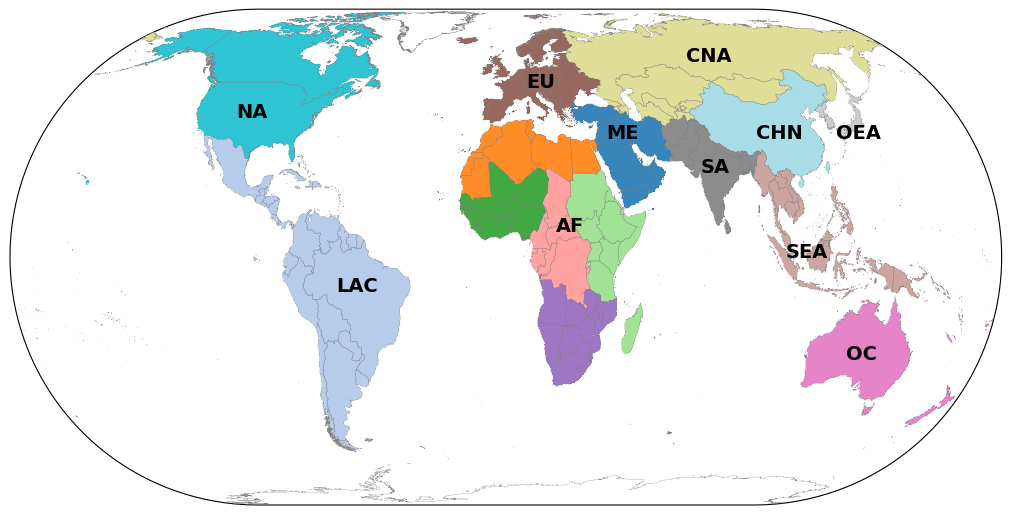

In [40]:
fig = plt.figure(figsize=(10, 8.5), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1, projection=ccrs.EckertIV())
display_extent_10km = [country_raster_10km_.bounds.left, country_raster_10km_.bounds.right, country_raster_10km_.bounds.bottom, country_raster_10km_.bounds.top]
ax1.imshow(np.where(region_mask_10km == 0, np.nan, region_mask_10km), interpolation='nearest', cmap='tab20', origin='upper', alpha=0.9, extent=display_extent_10km, zorder=5)
world_map.plot(color='none', edgecolor='grey', lw=0.2, ax=ax1, zorder=10)

fig.text(0.23, 0.665, 'NA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.33, 0.46, 'LAC', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.52, 0.70, 'EU', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.55, 0.53, 'AF', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.60, 0.64, 'ME', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.68, 0.73, 'CNA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.75, 0.64, 'CHN', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.83, 0.64, 'OEA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.695, 0.60, 'SA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.78, 0.50, 'SEA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.84, 0.38, 'OC', fontsize=14, fontdict={'weight': 'semibold'})

plt.show()
# fig.savefig(f'../figures/region-masks.jpg', dpi=600, bbox_inches='tight')

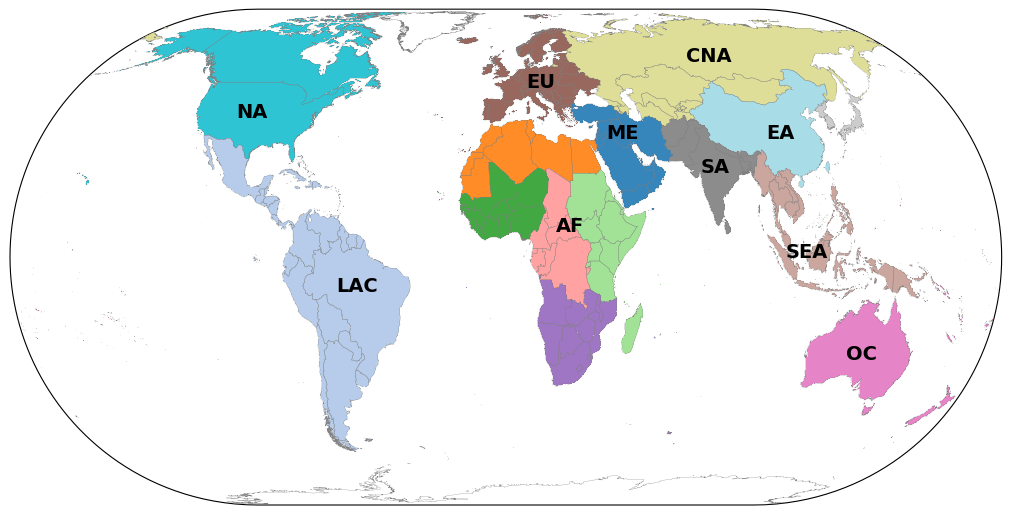

In [29]:
fig = plt.figure(figsize=(10, 8.5), constrained_layout=True)

ax1 = plt.subplot(1, 1, 1, projection=ccrs.EckertIV())
display_extent_10km = [country_raster_10km_.bounds.left, country_raster_10km_.bounds.right, country_raster_10km_.bounds.bottom, country_raster_10km_.bounds.top]
ax1.imshow(np.where(region_mask_10km == 0, np.nan, region_mask_10km), interpolation='nearest', cmap='tab20', origin='upper', alpha=0.9, extent=display_extent_10km, zorder=5)
world_map.plot(color='none', edgecolor='grey', lw=0.2, ax=ax1, zorder=10)

fig.text(0.23, 0.665, 'NA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.33, 0.46, 'LAC', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.52, 0.70, 'EU', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.55, 0.53, 'AF', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.60, 0.64, 'ME', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.68, 0.73, 'CNA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.76, 0.64, 'EA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.695, 0.60, 'SA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.78, 0.50, 'SEA', fontsize=14, fontdict={'weight': 'semibold'})
fig.text(0.84, 0.38, 'OC', fontsize=14, fontdict={'weight': 'semibold'})

plt.show()
fig.savefig(f'../figures/region-masks.jpg', dpi=600, bbox_inches='tight')

In [30]:
Path(r'../results/region-masks').mkdir(parents=True, exist_ok=True)

In [31]:
with rio.open(
    r'../results/region-masks/region-mask-1km.tif', 
    'w', 
    driver='GTiff', 
    height=region_mask_1km.shape[0],
    width=region_mask_1km.shape[1],
    count=1, 
    dtype=region_mask_1km.dtype, 
    crs=country_raster_1km_.crs, 
    transform=country_raster_1km_.transform, 
    compress='lzw'
    ) as dst:
    dst.write(region_mask_1km, 1)

In [32]:
with rio.open(
    r'../results/region-masks/region-mask-10km.tif', 
    'w', 
    driver='GTiff', 
    height=region_mask_10km.shape[0],
    width=region_mask_10km.shape[1],
    count=1, 
    dtype=region_mask_10km.dtype, 
    crs=country_raster_10km_.crs, 
    transform=country_raster_10km_.transform, 
    compress='lzw'
    ) as dst:
    dst.write(region_mask_10km, 1)

In [33]:
with rio.open(
    r'../results/region-masks/region-mask-50km.tif', 
    'w', 
    driver='GTiff', 
    height=region_mask_50km.shape[0],
    width=region_mask_50km.shape[1],
    count=1, 
    dtype=region_mask_50km.dtype, 
    crs=country_raster_50km_.crs, 
    transform=country_raster_50km_.transform, 
    compress='lzw'
    ) as dst:
    dst.write(region_mask_50km, 1)

20251106

In [34]:
usa = gpd.read_file('../data/gadm41_USA_shp/gadm41_USA_1.shp').to_crs("ESRI:54012")
can = gpd.read_file('../data/gadm41_CAN_shp/gadm41_CAN_1.shp').to_crs("ESRI:54012")
chn = gpd.read_file('../data/China-map/省.shp').to_crs("ESRI:54012")

In [35]:
usa_state_shapes = [(a_shape, a_value) for a_shape, a_value in zip(usa.geometry, [i for i in range(1, len(usa)+1)])]
can_state_shapes = [(a_shape, a_value) for a_shape, a_value in zip(can.geometry, [i for i in range(len(usa)+1, len(usa)+1+len(can))])]
chn_province_shapes = [(a_shape, a_value) for a_shape, a_value in zip(chn.geometry, [i for i in range(1, len(chn)+1)])]

In [36]:
CAN_USA_raster_1km = rasterize(
    shapes=usa_state_shapes+can_state_shapes, 
    out_shape=country_raster_1km_.shape, 
    fill=0, 
    transform=country_raster_1km_.transform,
    dtype=np.uint8)

In [37]:
CHN_raster_1km = rasterize(
    shapes=chn_province_shapes, 
    out_shape=country_raster_1km_.shape, 
    fill=0, 
    transform=country_raster_1km_.transform,
    dtype=np.uint8)

In [38]:
state_raster_1km = np.where((country_raster_1km == 116) | (country_raster_1km == 75), CHN_raster_1km, country_raster_1km)
state_raster_1km = np.where((state_raster_1km == 94) | (state_raster_1km == 246), CAN_USA_raster_1km, state_raster_1km)

In [39]:
with rio.open(
    r'../results/country-rasters/state-raster-eck4-1km.tif',
    'w',
    driver='GTiff',
    height=country_raster_1km_.shape[0],
    width=country_raster_1km_.shape[1],
    count=1,
    dtype=state_raster_1km.dtype, 
    # crs=raster_1km_.crs,
    crs=country_raster_1km_.crs,
    transform=country_raster_1km_.transform,
    compress='lzw',
) as dst:
    dst.write(state_raster_1km, 1)